In [ ]:
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Load data and General Plot

Use this script to plot calibration data from calibration.py


<>:105: SyntaxWarning: invalid escape sequence '\D'
<>:105: SyntaxWarning: invalid escape sequence '\D'
C:\Users\jesus\AppData\Local\Temp\ipykernel_14716\2175902007.py:105: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("Temperature difference, $\Delta T$ [°C]")


[[-7.38002870e-01  2.31292889e-02  1.02239674e+00  1.58934169e-03]
 [ 2.38135897e+01  1.21019807e-01  1.14650676e+00  2.22029319e-03]
 [ 4.76273612e+01  2.21693200e-01  1.19230613e+00  2.84121375e-03]
 [ 7.12274646e+01  3.44785080e-01  1.21592611e+00  2.54306384e-03]
 [ 9.53313063e+01  4.86112445e-01  1.26162365e+00  3.76257760e-03]
 [ 1.19586209e+02  6.41113223e-01  1.29512556e+00  5.36251012e-03]
 [ 1.43961019e+02  8.22013557e-01  1.21438933e+00  4.13274343e-03]
 [ 1.69021194e+02  1.00518542e+00  1.35862461e+00  4.86562405e-03]
 [ 1.45501642e+02  8.07888570e-01  1.21335432e+00  3.39040697e-03]
 [ 1.21655298e+02  6.17758311e-01  1.25904551e+00  1.98770587e-03]
 [ 9.79699316e+01  4.54607712e-01  1.27194916e+00  3.50447831e-03]
 [ 7.41884366e+01  3.18692639e-01  1.15321557e+00  2.07732067e-03]
 [ 5.04097888e+01  1.93905532e-01  1.19107531e+00  4.20193788e-03]
 [ 2.63679379e+01  9.33669898e-02  1.14187475e+00  1.99950761e-03]
 [-2.62625201e-01  1.07233696e-02  1.02734492e+00  9.70407682e

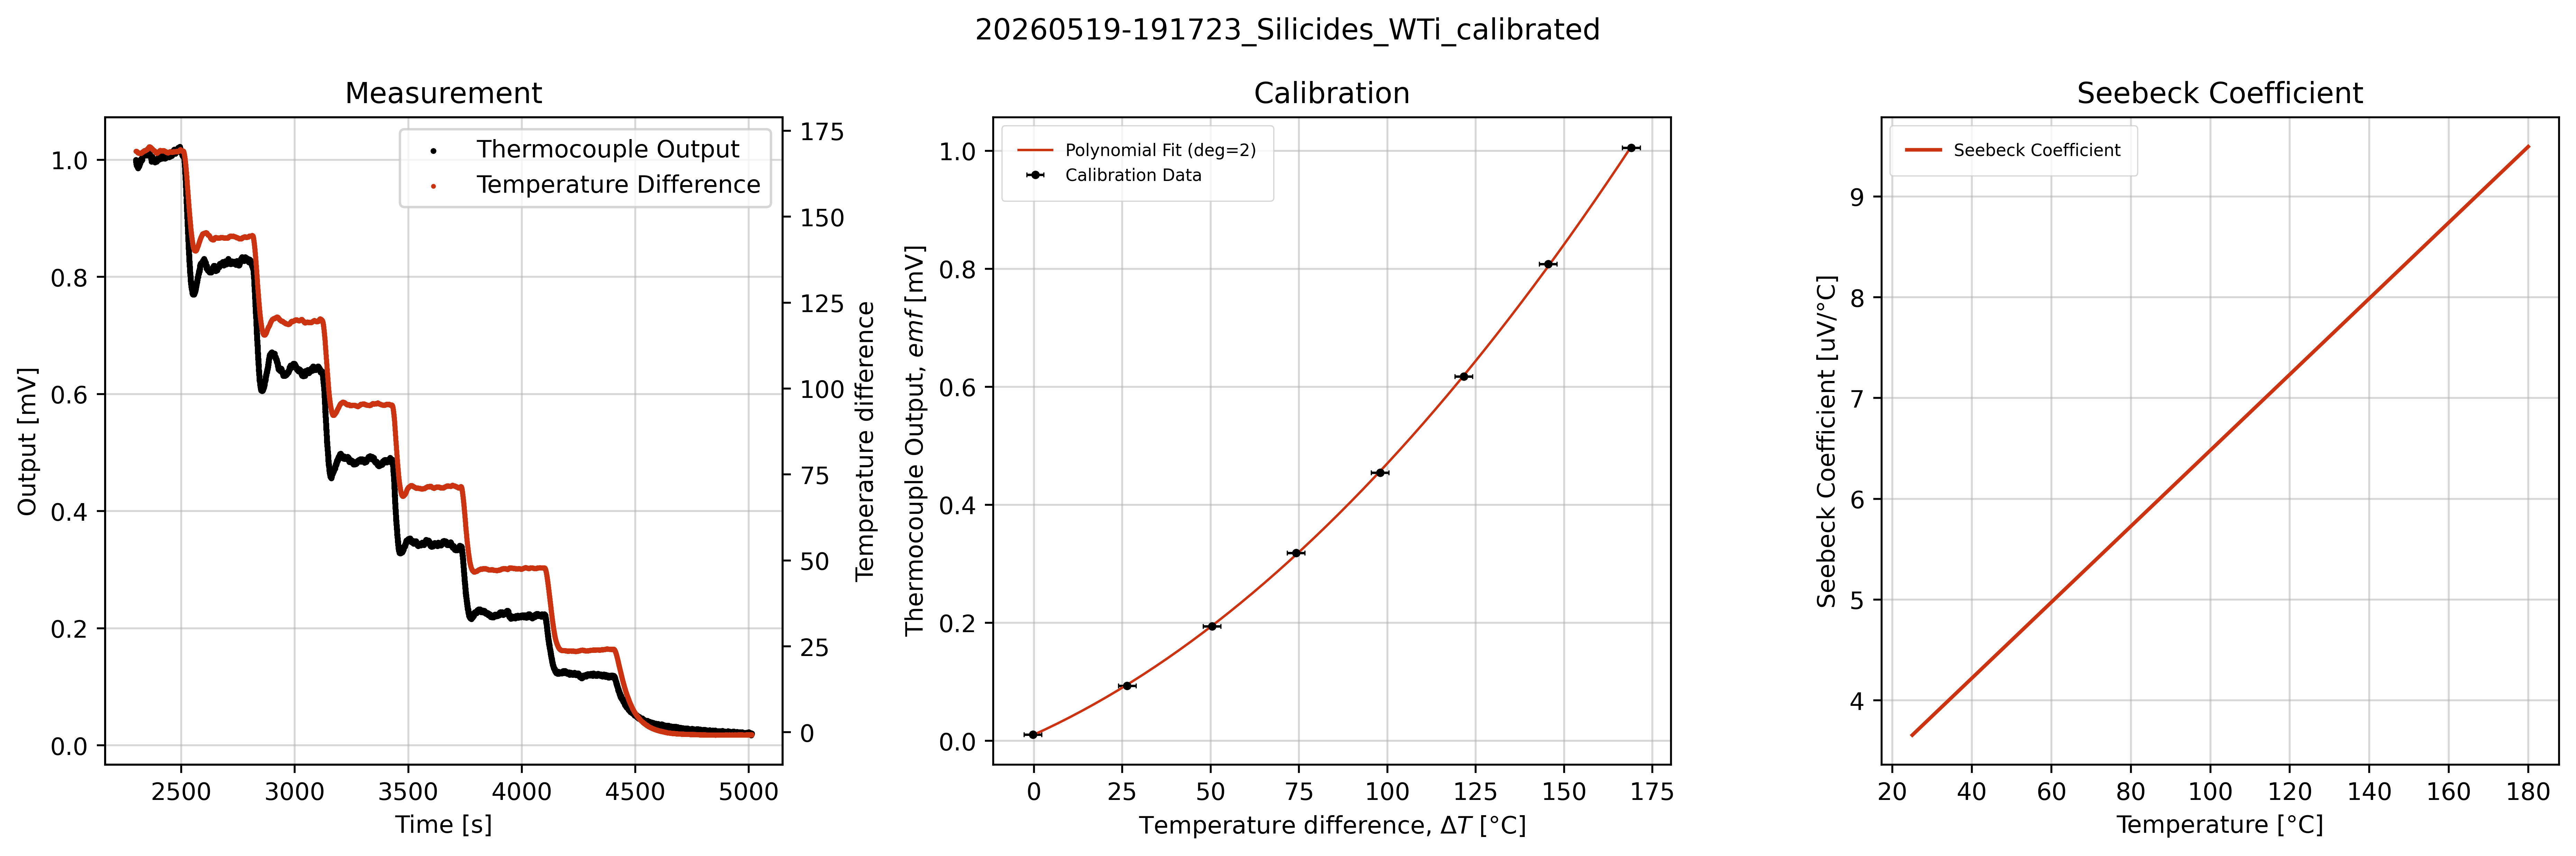

In [ ]:
### Loading data ------------------------------------------------------------------------------------------------------------------------

folder = "data/"
filename = "20260519-191723__calibrated"
con = sqlite3.connect(folder+filename+".db")
cur = con.cursor()

cur.execute("SELECT * FROM calibration")
cal_data = np.array(cur.fetchall())
cal_data = np.flip(cal_data,axis=0)
print(cal_data)

cur.execute("SELECT * FROM measurement")
rows = np.array(cur.fetchall())
measurement_data = np.vstack((rows[:, :], rows[:, :]))

con.close()

### Cropping the data ------------------------------------------------------------------------------------------------------------------------
crop = True

if crop:
    time_crop = [2300,24000]
    measurement_data = measurement_data[(measurement_data[:,0]>time_crop[0]) & (measurement_data[:,0]<time_crop[1]),:]

    cal_crop = [7,80]
    cal_data = cal_data[cal_crop[0]:cal_crop[1],:]

invert_polarity = False

if invert_polarity:
    measurement_data[:,1] = -measurement_data[:,1]
    cal_data[:,1] = -cal_data[:,1]

### Plotting ------------------------------------------------------------------------------------------------------------------------

fig,axes = plt.subplots(1,3,figsize=(15,5),dpi=500)

fig.suptitle(filename)

meas_output_settings = {
    "s" : 2,
    "c" : "black",
    "zorder" : +10,
    "label" : "Thermocouple Output"
}

meas_dt_settings = {
    "s" : 1,
    "c" : "#CC3311",
    "zorder" : -10,
    "alpha" : 1,
    "label" : "Temperature Difference"
}

grid_settings = {
    "alpha" : 0.5,
    "zorder" : -100,
}

# Measurement data

ax = axes[0]
ax2 = ax.twinx()
output_line = ax.scatter(measurement_data[:,0],measurement_data[:,1],**meas_output_settings)
dt_line = ax2.scatter(measurement_data[:,0],measurement_data[:,2]-measurement_data[:,3],**meas_dt_settings)

ax.set_ylabel("Output [mV]")
ax2.set_ylabel("Temperature difference")
ax.set_xlabel("Time [s]")
ax.set_title("Measurement")
if invert_polarity:
    ax.set_title("Measurement (inverted)")
lines = [output_line,dt_line]
ax.legend(lines,[l.get_label() for l in lines])
ax.grid(**grid_settings)


# Calibration

ax = axes[1]
ax.errorbar(cal_data[:,0],cal_data[:,1], 
            xerr = 2.5, #xerr=cal_data[:,2]+.05*cal_data[:,0],#yerr=cal_data[:,3],
            elinewidth=1,capthick=0.5, ecolor="black",
            fmt=".",capsize=1,markersize=5,color="black",label="Calibration Data")

# Polynomial Regression

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(cal_data[:,0].reshape(-1,1))
reg_poly = LinearRegression()
reg_poly.fit(X_poly,cal_data[:,1].reshape(-1,1))

x_fit_poly = np.linspace(cal_data[0,0],cal_data[-1,0])
X_fit_poly = poly.transform(x_fit_poly.reshape(-1,1))
fit_poly = reg_poly.predict(X_fit_poly)
ax.plot(x_fit_poly,fit_poly,c="#CC3311",lw=1,label="Polynomial Fit (deg=2)")

ax.grid(alpha=0.5,zorder=-10)
ax.set_axisbelow(True)
legend = ax.legend(fontsize=7,borderpad=1)
legend.get_frame().set_linewidth(0.5)

ax.set_xlabel("Temperature difference, $\Delta T$ [°C]")
ax.set_ylabel("Thermocouple Output, $emf$ [mV]")
ax.set_title("Calibration")
if invert_polarity:
    ax.set_title("Calibration (inverted)")

print(f"Polynomial Regression R^2: {reg_poly.score(X_poly,cal_data[:,1].reshape(-1,1))}")
print(f"Polynomial Regression Coefficients: {reg_poly.coef_}")

# Seebeck coefficient


S_coeffs = np.zeros(len(reg_poly.coef_[0])-1)
for i in range(len(reg_poly.coef_[0])-1):
    S_coeffs[i] = (i+1) * reg_poly.coef_[0][i+1]*1000

print("Seebeck Coefficients:", S_coeffs)
S = lambda T : sum(a*T**(i) for i,a in enumerate(S_coeffs))  

ax = axes[2]
T_range = np.linspace(25,180)
ax.plot(T_range,S(T_range),
        c = "#CC3311",
        label = "Seebeck Coefficient")

ax.grid(alpha=0.5,zorder=-10)
ax.set_axisbelow(True)
ax.set_title("Seebeck Coefficient")
legend = ax.legend(fontsize=7,borderpad=1)
legend.get_frame().set_linewidth(0.5)

ax.set_ylabel("Seebeck Coefficient [uV/°C]")
ax.set_xlabel("Temperature [°C]")

fig.tight_layout()

In [ ]:
filename = "20251105-150549_NewSetup"
con = sqlite3.connect("data/"+filename+".db")
cur = con.cursor()
cur.execute("SELECT * FROM measurement")
data = np.array(cur.fetchall())

# display(data)

fig,ax = plt.subplots(2,1,figsize=(8,5))
# increment = [data[i,0]-data[i-1,0] for i in range(1,10000)]
ax[0].plot(data[:,0],data[:,1],label="TFTC")
ax[1].plot(data[:,0],data[:,2],label="Hot Junction",c="r")
ax[1].plot(data[:,0],data[:,3],label="Cold Junction",c="b")
# ax.plot(increment,lw=1)
print(type(data))

ax[0].grid(alpha=0.5, zorder=-10)
ax[1].grid(alpha=0.5, zorder=-10)
ax[1].set_xlabel("time [s]")
ax[0].set_ylabel("Voltage output [mV]")
ax[1].set_ylabel("Control Temperature [°C]")
ax[0].legend()
ax[1].legend()
fig.suptitle(filename)
# fig.suptitle("")

# ax[1].set_ylim((20,30))
# ax[0].set_ylim((8,13))

# for axis in ax:
    # axis.set_xlim([750,1250])


# con.close()



In [ ]:
fig,ax = plt.subplots(figsize=(9,5))
fig.suptitle(filename)

ax.plot(data[:,0],data[:,1],c="gray",label="TFTC Output")
ax2 = ax.twinx()
ax2.plot(data[:,0],data[:,2],c="r",lw=1,label="Hot Junction")
ax2.plot(data[:,0],data[:,3],c="b",lw=1,label="Cold Junction")

ax.set_xlim([0,3000])
ax.set_ylim([0,20])
ax2.set_ylim([0,200])

ax.set_ylabel("Voltage output [mV]")
ax2.set_ylabel("Control temperature [°C]")
ax.set_xlabel("time [s]")

ax.legend(loc=(0.01,0.78))
ax2.legend(loc="upper left")
ax.grid(alpha=0.5,zorder=-10)


In [ ]:
df = pd.DataFrame(data,columns=("time","emf","HJ","CJ"))
df["DeltaT"] = df["HJ"]-df["CJ"]

df = df.sort_values(by=["DeltaT"])
df = df.reset_index(drop=True)


fig,ax = plt.subplots(1,1,figsize=(5,5))
ax.scatter(df["DeltaT"],df["emf"],s=1)
ax.set_ylabel("emf [mV]")
ax.set_xlabel("$\Delta$T [°C]")

In [ ]:
fit_points = [
    [9800, 10200],
    [8800, 9200],
    [7900, 8300],
    [7100, 7400],
    [5750, 6200],
    [5100, 5300],
    [4400, 4650],
    [3050, 3250],
    [2400, 2700],
    [1950, 2075]
]


for i in fit_points:
    xlow = i[0]-1.5*(i[1]-i[0])
    xhigh = i[1]+0.25*(i[1]-i[0])

    # Create DataFrame
    df = pd.DataFrame(data,columns=("time","emf","HJ","CJ"))
    df["DeltaT"] = df["HJ"]-df["CJ"]

    

    df_cropped = df.loc[(df["time"]>xlow) & (df["time"]<xhigh)]

    fig, ax = plt.subplots(2,2,figsize=(20,5))

    ax[0,0].plot(df["time"],df["emf"])
    ax[0,0].fill_between(df_cropped["time"], -100,100,
                    color = "yellow",
                    alpha=0.25
                    )
    ax[0,0].set_ylim((-5,45))




    ax[1,0].plot(df_cropped["time"],df_cropped["emf"])
    ax[1,0].set_xlim((xlow,xhigh))

    # ax[1].plot(df_cropped["time"],df_cropped["HJ"],alpha=0.3)
    # ax[1].plot(df_cropped["time"],df_cropped["CJ"],alpha=0.3)


    ax2 = ax[1,0].twinx()
    # ax2.plot(data[:,0],data[:,2],c="r",lw=1,label="Hot Junction")
    # ax2.plot(data[:,0],data[:,3],c="b",lw=1,label="Cold Junction")
    ax2.plot(df_cropped["time"],df_cropped["DeltaT"])

    for axis in ax[:,0]:
        axis.grid(alpha=0.5, zorder=-10)


    df = df.sort_values(by=["DeltaT"])
    df = df.reset_index(drop=True)



    xlow = i[0]
    xhigh = i[1]
    ax[1,0].axvline(xlow,c="r")
    ax[1,0].axvline(xhigh,c="r")

    df_fit = df.loc[(df["time"]>xlow) & (df["time"]<xhigh)]

    # display(df)



    reg = LinearRegression()
    reg.fit(df_fit["DeltaT"].values.reshape(-1,1),df_fit["emf"].values.reshape(-1,1))

    x_fit = np.linspace(df_fit["DeltaT"].iloc[0],df_fit["DeltaT"].iloc[-1]).reshape(-1,1)
    fit = reg.predict(x_fit)


    # fig,ax = plt.subplots(1,1,figsize=(10,10))
    gs = ax[0, 1].get_gridspec()
    ax[0,1].remove()
    ax[1,1].remove()
    axb = fig.add_subplot(gs[:,1])
    axb.scatter(df_fit["DeltaT"],df_fit["emf"],s=1)
    axb.plot(x_fit,fit,c="black")
    axb.axvline(df_fit["DeltaT"].mean(),c="r")
    axb.axhline(df_fit["emf"].mean(),c="r")
    

    ax[0,0].set_ylabel("emf [mV]")
    ax[0,0].set_xlabel("time [s]")
    ax[1,0].set_ylabel("emf [mV]")
    ax[1,0].set_xlabel("time [s]")
    axb.set_ylabel("emf [mV]")
    axb.set_xlabel("$\Delta$T [°C]")

    fig.tight_layout()

In [ ]:
fit_points = [
    [9800, 10200],
    [8800, 9200],
    [7900, 8300],
    [7100, 7400],
    [5750, 6200],
    [5100, 5300],
    [4400, 4650],
    [3050, 3250],
    [2400, 2700],
    [1950, 2075]
]

# Create DataFrame
df = pd.DataFrame(data,columns=("time","emf","HJ","CJ"))
df["DeltaT"] = df["HJ"]-df["CJ"]

def fitDatapoint(fit_points):
    xlow, xhigh = fit_points

    df_fit = df.loc[(df["time"]>xlow) & (df["time"]<xhigh)]


    DeltaT = df_fit["DeltaT"].mean()
    emf = df_fit["emf"].mean()

    # reg = LinearRegression()
    # reg.fit(df_fit["DeltaT"].values.reshape(-1,1),df_fit["emf"].values.reshape(-1,1))
    
    return DeltaT, emf



DeltaT = np.array([])
emf = np.array([])

for point in fit_points:
    res = fitDatapoint(point)
    DeltaT = np.append(DeltaT,res[0])
    emf = np.append(emf,res[1])

fig,ax = plt.subplots(1,1,figsize=(7,5))
ax.grid(alpha=0.3)
ax.scatter(DeltaT,emf,zorder=10)
reg = LinearRegression()
reg.fit(DeltaT.reshape(-1,1),emf.reshape(-1,1))
x_fit = np.linspace(DeltaT[0],DeltaT[-1]).reshape(-1,1)
fit = reg.predict(x_fit)
ax.plot(x_fit,fit,c="r")
ax.set_axisbelow(True)
ax.set_xlabel("$\\Delta T~[°C]$")
ax.set_ylabel("$emf~[mV]$")

ax.annotate(f"$R^2$ = {round(reg.score(DeltaT.reshape(-1,1),emf.reshape(-1,1)),4)}",xy=(0.15,0.85),xycoords="subfigure fraction")
ax.annotate(f"$S$ = {round(reg.coef_[0][0]*1000)} $\\mu$V/°C",xy=(0.15,0.8),xycoords="subfigure fraction")

print("Är det inte underbart?")


# Manual Data Treatment

Polynomial coefficients (2nd order): [1.60770459e-05 2.95812122e-03 2.21958199e-02]
Fit equation: 0.000016x² + 0.002958x + 0.022196


<>:67: SyntaxWarning: invalid escape sequence '\D'
<>:93: SyntaxWarning: invalid escape sequence '\m'
<>:67: SyntaxWarning: invalid escape sequence '\D'
<>:93: SyntaxWarning: invalid escape sequence '\m'
C:\Users\jesus\AppData\Local\Temp\ipykernel_14716\396202901.py:67: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("$\Delta$T [°C]")
C:\Users\jesus\AppData\Local\Temp\ipykernel_14716\396202901.py:93: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel("Seebeck Coefficient [$\mu$V/°C]")


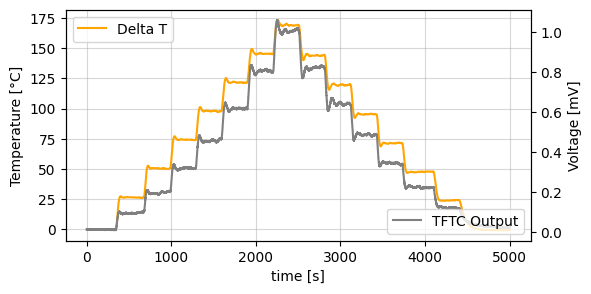

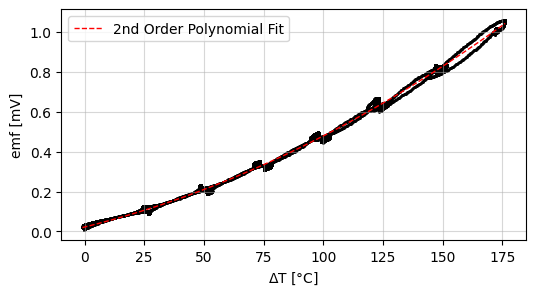

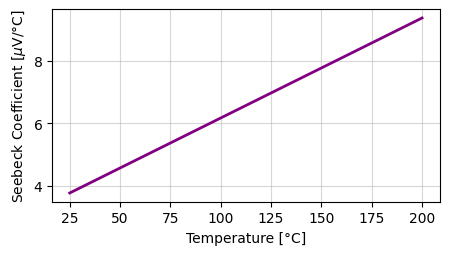

In [ ]:
filename = "20260519-191723_"
con = sqlite3.connect("data/raw/"+filename+".db")
cur = con.cursor()
cur.execute("SELECT * FROM measurement")
data_array = np.array(cur.fetchall())
con.close()

fig,ax = plt.subplots(1,1,figsize=(6,3),dpi=100)
ax2 = ax.twinx()

data = pd.DataFrame(data_array,columns=("time","emf","HJ","CJ","HJ2"))

truncate_range = (data["time"]>000) & (data["time"]<5000)
# truncate_range = (data["time"]>1000) & (data["time"]<data["time"].max())

data_raw = data.loc[truncate_range]

data = data_raw

# data = data_raw.loc[((data_raw["time"]>300) & (data_raw["time"]<800)) | 
#                     ((data_raw["time"]>1000) & (data_raw["time"]<1400)) |
#                     ((data_raw["time"]>1700) & (data_raw["time"]<2100)) |
#                     ((data_raw["time"]>2400) & (data_raw["time"]<2800)) |
#                     ((data_raw["time"]>3000) & (data_raw["time"]<3500)) |
#                     ((data_raw["time"]>3800) & (data_raw["time"]<4200)) |
#                     ((data_raw["time"]>4500) & (data_raw["time"]<5000))]


# t_range = (data["time"]>5000) & (data["time"]<5500)

# data = data.loc[t_range]

# ax.plot(data["time"],data["CJ"],c="blue",label="Cold Junction")
# ax.plot(data["time"],data["HJ"],c="red",label="Hot Junction")
# ax.plot(data["time"],data["HJ2"],c="green",label="Hot Junction 2")
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)**1.8,c="orange",label="Delta T",lw=.5)
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.exp(np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)),c="orange",label="Delta T",lw=.5)
ax.plot(data["time"],data["HJ"]-data["CJ"],c="orange",label="Delta T")
# ax.plot(data["time"],np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0),c="orange",label="Delta T")
ax2.plot(data["time"],data["emf"],c="gray",label="TFTC Output")
ax.set_xlabel("time [s]")
ax.set_ylabel("Temperature [°C]")
ax2.set_ylabel("Voltage [mV]")
ax.legend(loc="upper left")
ax2.legend(loc="lower right")
ax.grid(alpha=0.5,zorder=-10)

division = 6900
series_limit = data["time"].searchsorted(division)
# ax.axvline(division,c="gray",ls="--")

fig,ax = plt.subplots(1,1,figsize=(6,3),dpi=100)
data["DeltaT"] = np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0) - data["CJ"]
ax.scatter(data["DeltaT"].iloc[:series_limit],data["emf"].iloc[:series_limit],s=1,c="black")
ax.scatter(data["DeltaT"].iloc[series_limit:],data["emf"].iloc[series_limit:],s=1,c="black")

data1 = data.iloc[:series_limit-100]
data2 = data.iloc[series_limit+100:]

# 2nd order polynomial fit
coeffs1 = np.polyfit(data1["DeltaT"], data1["emf"], 2)
poly = np.poly1d(coeffs1)
x_fit = np.linspace(data1["DeltaT"].min(), data1["DeltaT"].max(), 100)
y_fit = poly(x_fit)

ax.plot(x_fit, y_fit, c="red", lw=1, ls="--", label="2nd Order Polynomial Fit")
ax.set_xlabel("$\Delta$T [°C]")
ax.set_ylabel("emf [mV]")
ax.legend()
ax.grid(alpha=0.5)

print(f"Polynomial coefficients (2nd order): {coeffs1}")
print(f"Fit equation: {coeffs1[0]:.6f}x² + {coeffs1[1]:.6f}x + {coeffs1[2]:.6f}")

# coeffs2 = np.polyfit(data2["DeltaT"], data2["emf"], 2)
# poly = np.poly1d(coeffs2)
# x_fit = np.linspace(data2["DeltaT"].min(), data2["DeltaT"].max(), 100)
# y_fit = poly(x_fit)

# ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
# ax.set_xlabel("$\Delta$T [°C]")
# ax.set_ylabel("emf [mV]")
# ax.legend()
# ax.grid(alpha=0.5)

# print(f"Polynomial coefficients (2nd order): {coeffs2}")
# print(f"Fit equation: {coeffs2[0]:.6f}x² + {coeffs2[1]:.6f}x + {coeffs2[2]:.6f}")

fig,ax = plt.subplots(1,1,figsize=(5,2.5),dpi=100)
T_range = np.linspace(25,200,100)
coeffs1 = coeffs1*1000
ax.plot(T_range,2*coeffs1[0]*T_range + coeffs1[1],c="purple",lw=2)
ax.set_ylabel("Seebeck Coefficient [$\mu$V/°C]")
ax.set_xlabel("Temperature [°C]")
ax.grid(alpha=0.5)
# T_range = np.linspace(0,200,100)
# coeffs2 = coeffs2*1000
# ax.plot(T_range,2*coeffs2[0]*T_range + coeffs2[1],c="purple",lw=2)




### If only one HJ reference

<>:56: SyntaxWarning: invalid escape sequence '\D'
<>:56: SyntaxWarning: invalid escape sequence '\D'
C:\Users\je7462ca\AppData\Local\Temp\ipykernel_19396\1652814936.py:56: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("$\Delta$T [°C]")


Polynomial coefficients (2nd order): [-5.13450466e-02  2.06806857e+01 -2.08122635e+03]
Fit equation: -0.051345x² + 20.680686x + -2081.226347


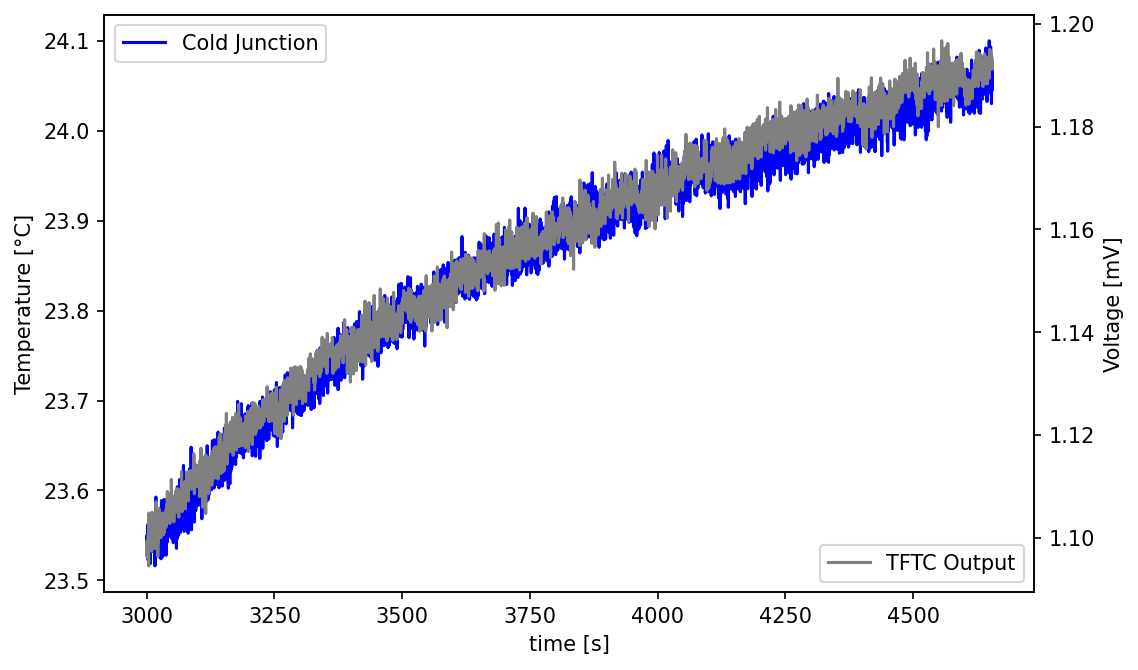

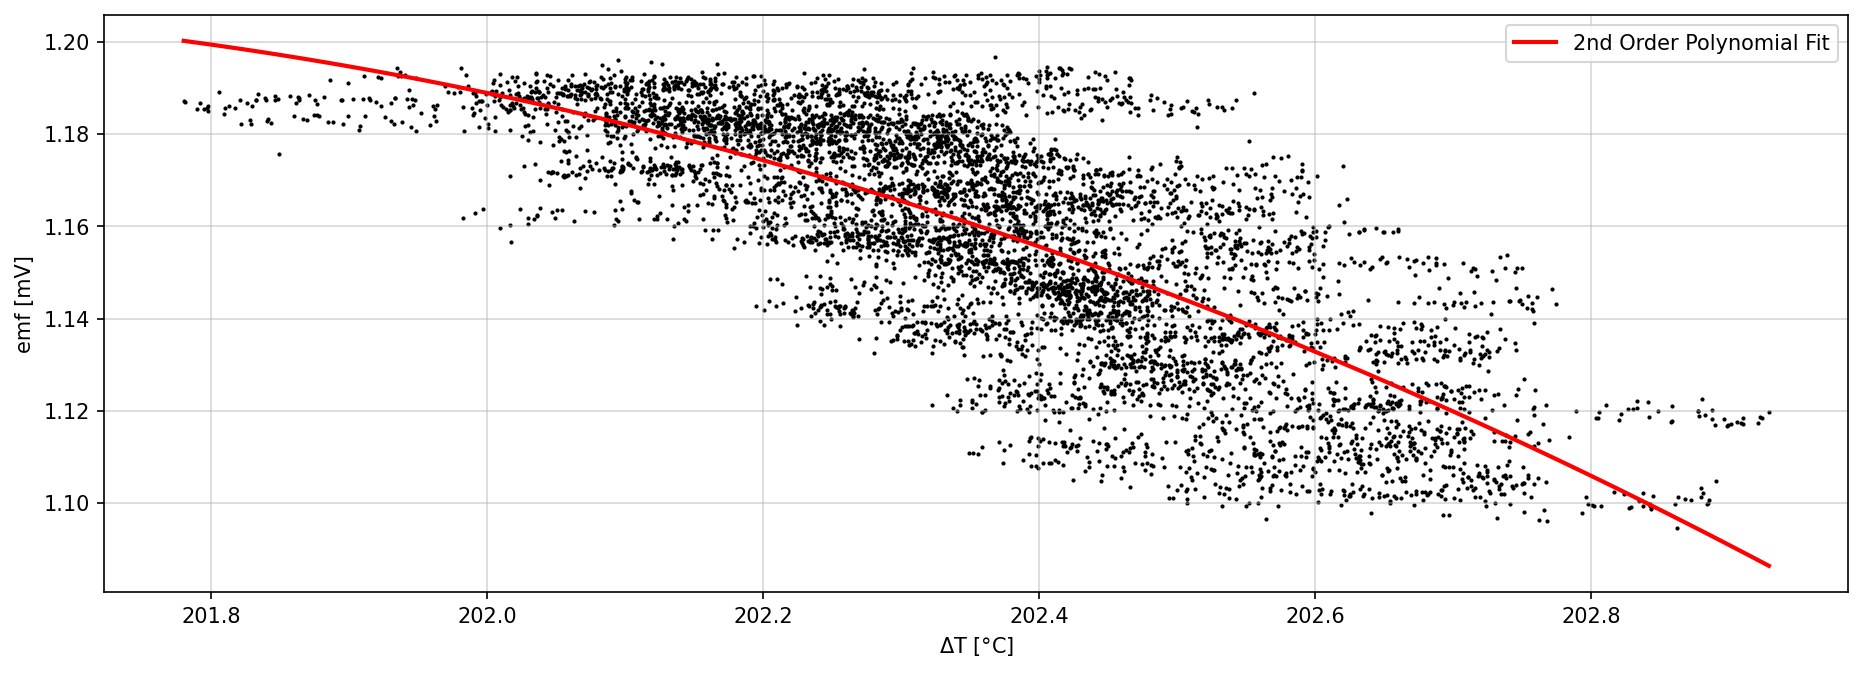

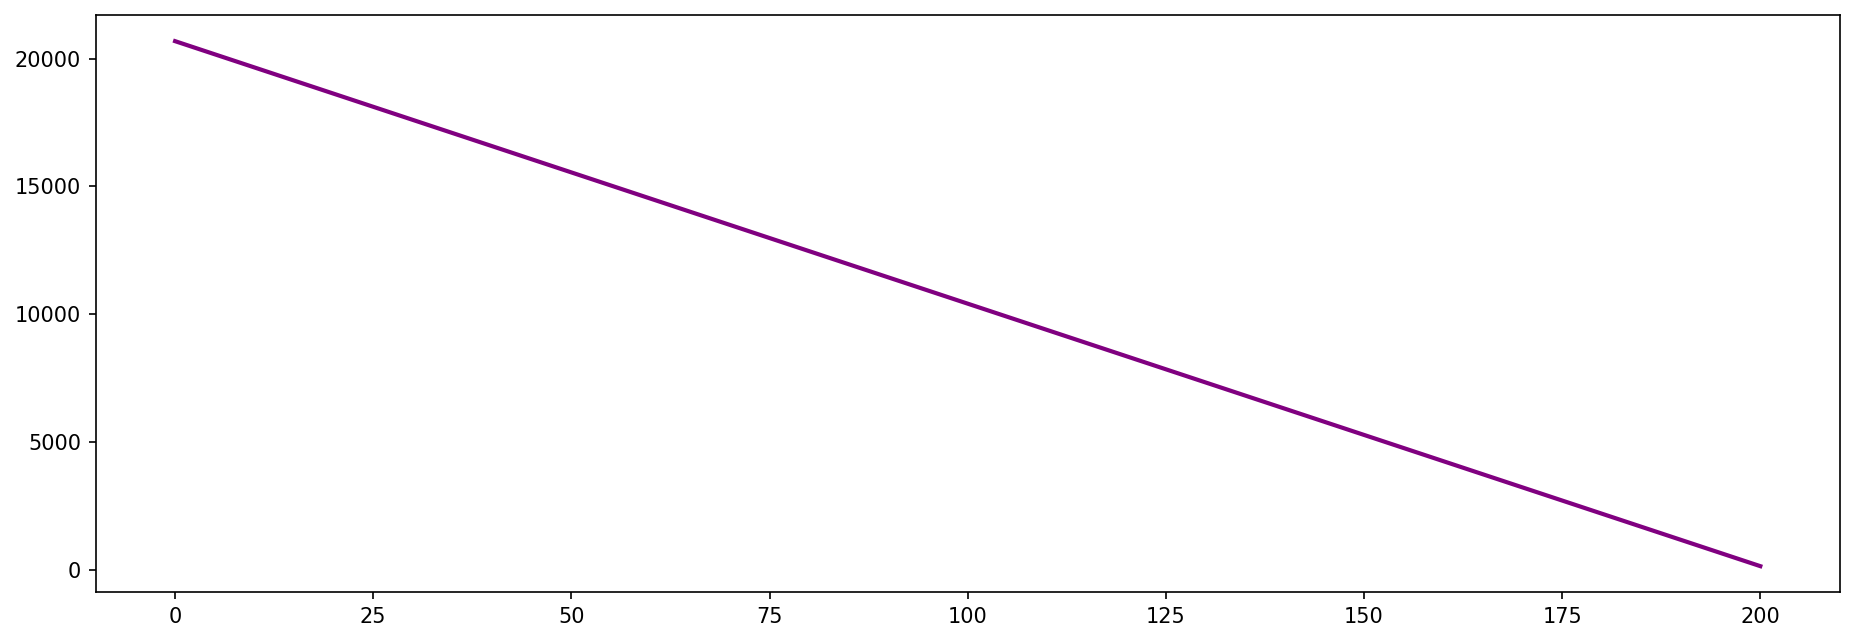

In [54]:
filename = "20251126-155003_K-type_2"
con = sqlite3.connect("data/"+filename+".db")
cur = con.cursor()
cur.execute("SELECT * FROM measurement")
data_array = np.array(cur.fetchall())
con.close()

fig,ax = plt.subplots(1,1,figsize=(8,5),dpi=150)
ax2 = ax.twinx()

data = pd.DataFrame(data_array,columns=("time","emf","HJ","CJ"))

truncate_range = (data["time"]>3000) & (data["time"]<data["time"].max())
# truncate_range = (data["time"]>3000) & (data["time"]<4000)#data["time"].max())


data = data.loc[truncate_range]


# t_range = (data["time"]>5000) & (data["time"]<5500)

# data = data.loc[t_range]

ax.plot(data["time"],data["CJ"],c="blue",label="Cold Junction")
# ax.plot(data["time"],data["HJ"],c="red",label="Hot Junction")
# ax.plot(data["time"],data["HJ2"],c="green",label="Hot Junction 2")
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)**1.8,c="orange",label="Delta T",lw=.5)
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.exp(np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)),c="orange",label="Delta T",lw=.5)
# ax.plot(data["time"],data["HJ"]-data["CJ"],c="orange",label="Delta T")
# ax.plot(data["time"],np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0),c="orange",label="Delta T")
ax2.plot(data["time"],data["emf"],c="gray",label="TFTC Output")
ax.set_xlabel("time [s]")
ax.set_ylabel("Temperature [°C]")
ax2.set_ylabel("Voltage [mV]")
# ax.set_ylim((195,205))
ax.legend()
ax2.legend(loc="lower right")

division = 6900
series_limit = data["time"].searchsorted(division)

fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
data["DeltaT"] = np.mean(np.array([data["HJ"]]),axis=0) - data["CJ"]
ax.scatter(data["DeltaT"].iloc[:series_limit],data["emf"].iloc[:series_limit],s=1,c="black")
ax.scatter(data["DeltaT"].iloc[series_limit:],data["emf"].iloc[series_limit:],s=1,c="black")

# data1 = data.iloc[:series_limit-100]

# 2nd order polynomial fit
coeffs1 = np.polyfit(data["DeltaT"], data["emf"], 2)
poly = np.poly1d(coeffs1)
x_fit = np.linspace(data["DeltaT"].min(), data["DeltaT"].max(), 100)
y_fit = poly(x_fit)

ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
ax.set_xlabel("$\Delta$T [°C]")
ax.set_ylabel("emf [mV]")
ax.legend()
ax.grid(alpha=0.5)

print(f"Polynomial coefficients (2nd order): {coeffs1}")
print(f"Fit equation: {coeffs1[0]:.6f}x² + {coeffs1[1]:.6f}x + {coeffs1[2]:.6f}")

# coeffs2 = np.polyfit(data2["DeltaT"], data2["emf"], 2)
# poly = np.poly1d(coeffs2)
# x_fit = np.linspace(data2["DeltaT"].min(), data2["DeltaT"].max(), 100)
# y_fit = poly(x_fit)

# ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
# ax.set_xlabel("$\Delta$T [°C]")
# ax.set_ylabel("emf [mV]")
# ax.legend()
# ax.grid(alpha=0.5)

# print(f"Polynomial coefficients (2nd order): {coeffs2}")
# print(f"Fit equation: {coeffs2[0]:.6f}x² + {coeffs2[1]:.6f}x + {coeffs2[2]:.6f}")

fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
T_range = np.linspace(0,200,100)
coeffs1 = coeffs1*1000
ax.plot(T_range,2*coeffs1[0]*T_range + coeffs1[1],c="purple",lw=2)
T_range = np.linspace(0,200,100)
# coeffs2 = coeffs2*1000
# ax.plot(T_range,2*coeffs2[0]*T_range + coeffs2[1],c="purple",lw=2)

In [ ]:
filename = "20251126-145004_K-type_2"
con = sqlite3.connect("data/"+filename+".db")
cur = con.cursor()
cur.execute("SELECT * FROM measurement")
data_array = np.array(cur.fetchall())
con.close()

fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
ax2 = ax.twinx()

data = pd.DataFrame(data_array,columns=("time","emf","HJ","CJ"))



# truncate_range = (data["time"]>0) & (data["time"]<200)

# data = data.loc[truncate_range]

t_range = (data["time"]>100) & (data["time"]<300)

data = data.loc[t_range]

# ax.plot(data["time"],data["CJ"],c="blue",label="Cold Junction")
ax.plot(data["time"],data["HJ"],c="red",label="Hot Junction")
# ax.plot(data["time"],data["HJ2"],c="green",label="Hot Junction 2")
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)**1.8,c="orange",label="Delta T",lw=.5)
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.exp(np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)),c="orange",label="Delta T",lw=.5)
# ax2.plot(data["time"],data["HJ"]-data["HJ2"],c="orange",label="Delta T")
# ax.plot(data["time"],np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0),c="orange",label="Delta T")
# ax2.plot(data["time"],data["emf"],c="gray",label="TFTC Output")
ax.set_xlabel("time [s]")
ax.set_ylabel("Temperature [°C] / Voltage [mV]")
ax.legend()

# ax2 = ax.twinx()
ax2.plot(data["time"],data["emf"],c="gray",label="TFTC Output")
ax2.set_ylabel("Voltage [mV]")
ax.set_xlabel("time [s]")
ax.legend()

# division = 6900
# series_limit = data["time"].searchsorted(division)
# ax.axvline(division,c="gray",ls="--")

# fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
# data["DeltaT"] = data["HJ"] - data["CJ"]
# ax.scatter(data["DeltaT"].iloc[:series_limit],data["emf"].iloc[:series_limit],s=1,c="black")
# ax.scatter(data["DeltaT"].iloc[series_limit:],data["emf"].iloc[series_limit:],s=1,c="black")

# data1 = data.iloc[:series_limit-100]
# data2 = data.iloc[series_limit+100:]

# # 2nd order polynomial fit
# coeffs1 = np.polyfit(data1["DeltaT"], data1["emf"], 2)
# poly = np.poly1d(coeffs1)
# x_fit = np.linspace(data1["DeltaT"].min(), data1["DeltaT"].max(), 100)
# y_fit = poly(x_fit)

# ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
# ax.set_xlabel("$\Delta$T [°C]")
# ax.set_ylabel("emf [mV]")
# ax.legend()
# ax.grid(alpha=0.5)

# print(f"Polynomial coefficients (2nd order): {coeffs1}")
# print(f"Fit equation: {coeffs1[0]:.6f}x² + {coeffs1[1]:.6f}x + {coeffs1[2]:.6f}")

# coeffs2 = np.polyfit(data2["DeltaT"], data2["emf"], 2)
# poly = np.poly1d(coeffs2)
# x_fit = np.linspace(data2["DeltaT"].min(), data2["DeltaT"].max(), 100)
# y_fit = poly(x_fit)

# ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
# ax.set_xlabel("$\Delta$T [°C]")
# ax.set_ylabel("emf [mV]")
# ax.legend()
# ax.grid(alpha=0.5)

# print(f"Polynomial coefficients (2nd order): {coeffs2}")
# print(f"Fit equation: {coeffs2[0]:.6f}x² + {coeffs2[1]:.6f}x + {coeffs2[2]:.6f}")

# fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
# T_range = np.linspace(0,200,100)
# coeffs1 = coeffs1*1000
# ax.plot(T_range,2*coeffs1[0]*T_range + coeffs1[1],c="purple",lw=2)
# T_range = np.linspace(0,200,100)
# coeffs2 = coeffs2*1000
# ax.plot(T_range,2*coeffs2[0]*T_range + coeffs2[1],c="purple",lw=2)


In [ ]:
filename = "20251216-094015_K-type_3_2"
con = sqlite3.connect("data/"+filename+".db")
cur = con.cursor()
cur.execute("SELECT * FROM measurement")
data_array = np.array(cur.fetchall())
con.close()

fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
ax2 = ax.twinx()

data = pd.DataFrame(data_array,columns=("time","emf","HJ","CJ","HJ2"))

truncate_range = (data["time"]>1000) & (data["time"]<data["time"].max())

data = data.loc[truncate_range]


# t_range = (data["time"]>5000) & (data["time"]<5500)

# data = data.loc[t_range]

# ax.plot(data["time"],data["CJ"],c="blue",label="Cold Junction")
ax.plot(data["time"],data["HJ"],c="red",label="Hot Junction")
ax.plot(data["time"],data["HJ2"],c="green",label="Hot Junction 2")
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)**1.8,c="orange",label="Delta T",lw=.5)
# ax2.plot(data["time"],abs(data["HJ"]-data["HJ2"])/np.exp(np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0)),c="orange",label="Delta T",lw=.5)
# ax2.plot(data["time"],data["HJ"]-data["HJ2"],c="orange",label="Delta T")
# ax.plot(data["time"],np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0),c="orange",label="Delta T")
ax2.plot(data["time"],data["emf"],c="gray",label="TFTC Output")
ax.set_xlabel("time [s]")
ax.set_ylabel("Temperature [°C] / Voltage [mV]")
ax.legend()

division = 6900
series_limit = data["time"].searchsorted(division)
ax.axvline(division,c="gray",ls="--")

fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
data["DeltaT"] = np.mean(np.array([data["HJ"],data["HJ2"]]),axis=0) - data["CJ"]
ax.scatter(data["DeltaT"].iloc[:series_limit],data["emf"].iloc[:series_limit],s=1,c="black")
ax.scatter(data["DeltaT"].iloc[series_limit:],data["emf"].iloc[series_limit:],s=1,c="black")

data1 = data.iloc[:series_limit-100]
data2 = data.iloc[series_limit+100:]

# 2nd order polynomial fit
coeffs1 = np.polyfit(data1["DeltaT"], data1["emf"], 2)
poly = np.poly1d(coeffs1)
x_fit = np.linspace(data1["DeltaT"].min(), data1["DeltaT"].max(), 100)
y_fit = poly(x_fit)

ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
ax.set_xlabel("$\Delta$T [°C]")
ax.set_ylabel("emf [mV]")
ax.legend()
ax.grid(alpha=0.5)

print(f"Polynomial coefficients (2nd order): {coeffs1}")
print(f"Fit equation: {coeffs1[0]:.6f}x² + {coeffs1[1]:.6f}x + {coeffs1[2]:.6f}")

coeffs2 = np.polyfit(data2["DeltaT"], data2["emf"], 2)
poly = np.poly1d(coeffs2)
x_fit = np.linspace(data2["DeltaT"].min(), data2["DeltaT"].max(), 100)
y_fit = poly(x_fit)

ax.plot(x_fit, y_fit, c="red", lw=2, label="2nd Order Polynomial Fit")
ax.set_xlabel("$\Delta$T [°C]")
ax.set_ylabel("emf [mV]")
ax.legend()
ax.grid(alpha=0.5)

print(f"Polynomial coefficients (2nd order): {coeffs2}")
print(f"Fit equation: {coeffs2[0]:.6f}x² + {coeffs2[1]:.6f}x + {coeffs2[2]:.6f}")

fig,ax = plt.subplots(1,1,figsize=(15,5),dpi=150)
T_range = np.linspace(0,200,100)
coeffs1 = coeffs1*1000
ax.plot(T_range,2*coeffs1[0]*T_range + coeffs1[1],c="purple",lw=2)
T_range = np.linspace(0,200,100)
coeffs2 = coeffs2*1000
ax.plot(T_range,2*coeffs2[0]*T_range + coeffs2[1],c="purple",lw=2)